Import the required libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


Load the dataset

In [8]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Explore the dataset

In [9]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDataset information:")
df.info()

print("\nFinal grade statistics:")
print(df["G3"].describe())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null   

Select input and output columns

In [10]:
X = df[[
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]]

y = df["G3"]

print("Input features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Input features:


,studytime,failures,absences,G1,G2
0,2,0,6,5,6
1,2,0,4,5,5
2,2,3,10,7,8
3,3,0,2,15,14
4,2,0,4,6,10



Target values:


,G3
0,6
1,6
2,10
3,15
4,10


Split the dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


Scale the input data

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Input features scaled successfully!")

Input features scaled successfully!


Build the ANN model

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(5,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

Train the model

In [14]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    verbose=1
)

print("ANN model training completed!")

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - loss: 123.3710 - mae: 10.2047 - val_loss: 119.7250 - val_mae: 10.2297
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 119.3304 - mae: 10.0000 - val_loss: 114.8797 - val_mae: 9.9935
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 114.6844 - mae: 9.7830 - val_loss: 109.2390 - val_mae: 9.7411
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 108.9227 - mae: 9.5473 - val_loss: 102.5268 - val_mae: 9.4414
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 102.0741 - mae: 9.2757 - val_loss: 94.6224 - val_mae: 9.0756
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 94.1218 - mae: 8.9418 - val_loss: 85.6893 - val_mae: 8.6321
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 85.1529 - mae: 8.5360 - val_loss: 76.0300 - val_mae: 8.1169
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 75.6799 - mae: 8.0707 - val_loss: 65.8793 - val_mae: 7.5288
Epoch 9/100
16/16 ━━━━━━━━━━

Evaluate the model

In [15]:
y_pred = model.predict(X_test_scaled).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
MAE: 1.44
MSE: 4.93
RMSE: 2.22
R2 Score: 0.76


Display the training graph

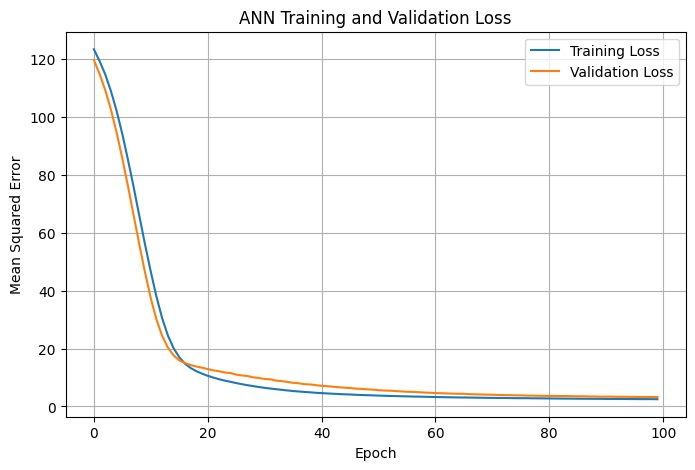

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()

Compare actual and predicted grades

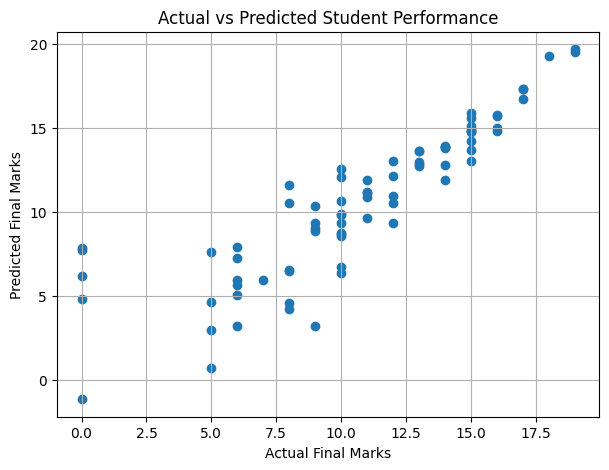

In [17]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Final Marks")
plt.ylabel("Predicted Final Marks")
plt.title("Actual vs Predicted Student Performance")
plt.grid(True)
plt.show()

Predict marks for a new student

In [18]:
new_student = pd.DataFrame(
    [[3, 0, 2, 12, 14]],
    columns=[
        "studytime",
        "failures",
        "absences",
        "G1",
        "G2"
    ]
)

new_student_scaled = scaler.transform(new_student)

predicted_marks = model.predict(new_student_scaled)[0][0]

predicted_marks = np.clip(predicted_marks, 0, 20)

print("Predicted Final Mathematics Marks:",
      round(float(predicted_marks), 2), "/ 20")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Predicted Final Mathematics Marks: 13.71 / 20
